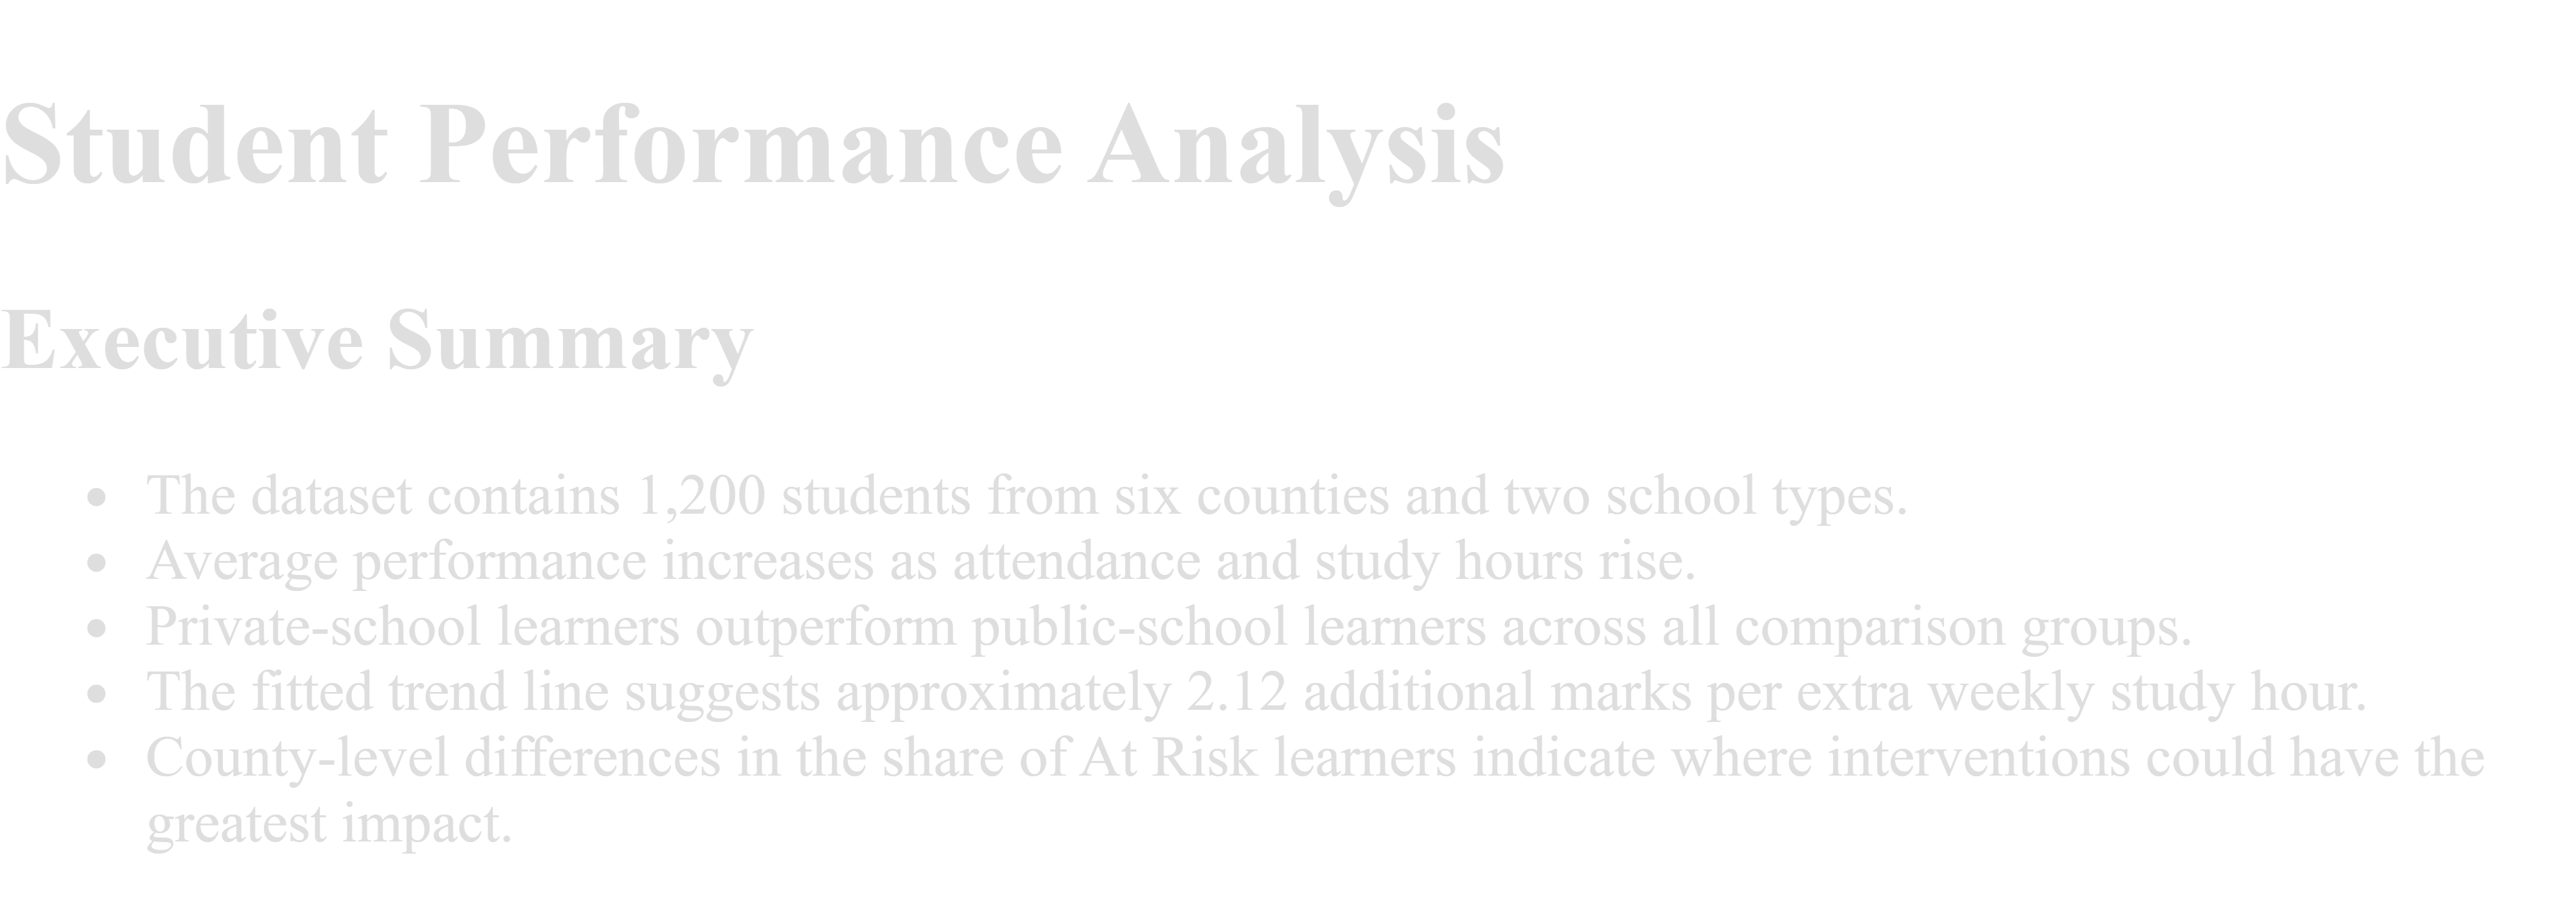

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
rng = np.random.default_rng(55)

n = 1200

students_gen = pd.DataFrame({
    "student_id": range(1, n + 1),
    "county": rng.choice(
        ["Nairobi", "Kisumu", "Nakuru",
         "Mombasa", "Nyeri", "Turkana"],
        n
    ),
    "school_type": rng.choice(
        ["Public", "Private"],
        n,
        p=[0.75, 0.25]
    ),
    "gender": rng.choice(
        ["F", "M"],
        n
    ),
    "attendance_rate": rng.beta(8, 2, n).round(2),
    "study_hours": rng.gamma(2.5, 2.0, n).round(1),
})

base = (
    35
    + 30 * students_gen["attendance_rate"]
    + 2.2 * students_gen["study_hours"]
    + np.where(
        students_gen["school_type"] == "Private",
        6,
        0
    )
)

students_gen["math"] = (
    base + rng.normal(0, 8, n)
).clip(0, 100).round(0)

students_gen["english"] = (
    base + rng.normal(3, 7, n)
).clip(0, 100).round(0)

students_gen["science"] = (
    base + rng.normal(-2, 9, n)
).clip(0, 100).round(0)

students_gen.to_csv(
    "student_performance.csv",
    index=False
)

print("student_performance.csv created.")

student_performance.csv created.


In [3]:
students = pd.read_csv(
    "student_performance.csv"
)

print(
    "Loaded successfully."
)

print(
    "Shape:",
    students.shape
)


Loaded successfully.
Shape: (1200, 9)


In [4]:
print("Dataset Shape:")
print(students.shape)

print("\nColumn Information")
students.info()

print("\nMissing Values")
print(students.isnull().sum())

print("\nDuplicate Rows")
print(students.duplicated().sum())

print("\nUnique Student IDs")
print(students["student_id"].nunique())

print("\nDuplicate Student IDs")
print(
    students["student_id"]
    .duplicated()
    .sum()
)

print("\nAttendance Range")
print(
    students["attendance_rate"].min(),
    students["attendance_rate"].max()
)

print("\nScore Range")
print(
    students[
        ["math","english","science"]
    ].agg(["min","max"])
)

Dataset Shape:
(1200, 9)

Column Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       1200 non-null   int64  
 1   county           1200 non-null   object 
 2   school_type      1200 non-null   object 
 3   gender           1200 non-null   object 
 4   attendance_rate  1200 non-null   float64
 5   study_hours      1200 non-null   float64
 6   math             1200 non-null   float64
 7   english          1200 non-null   float64
 8   science          1200 non-null   float64
dtypes: float64(5), int64(1), object(3)
memory usage: 84.5+ KB

Missing Values
student_id         0
county             0
school_type        0
gender             0
attendance_rate    0
study_hours        0
math               0
english            0
science            0
dtype: int64

Duplicate Rows
0

Unique Student IDs
1200

Duplicate Student 

In [5]:
students["average_score"] = (
    students[
        ["math", "english", "science"]
    ]
    .mean(axis=1)
    .round(2)
)

students["performance_band"] = pd.cut(
    students["average_score"],
    bins=[-np.inf, 59.99, 74.99, np.inf],
    labels=[
        "At Risk",
        "Meeting",
        "Exceeding"
    ]
)

students[
    [
        "student_id",
        "average_score",
        "performance_band"
    ]
].head()

,student_id,average_score,performance_band
0,1,75.0,Exceeding
1,2,92.0,Exceeding
2,3,87.0,Exceeding
3,4,82.0,Exceeding
4,5,69.0,Meeting


In [6]:
# Numerical variables

num_cols = [
    "attendance_rate",
    "study_hours",
    "math",
    "english",
    "science",
    "average_score"
]

uni_summary = pd.DataFrame({
    "Mean": students[num_cols].mean(),
    "Median": students[num_cols].median(),
    "Std Dev": students[num_cols].std(),
    "IQR": (
        students[num_cols].quantile(0.75)
        - students[num_cols].quantile(0.25)
    ),
    "Skewness": students[num_cols].skew()
}).round(2)

print("=== Numerical Summary ===")
print(uni_summary)

# Save report
uni_summary.to_csv(
    "reports/univariate_summary.csv"
)

print("\nSaved to reports/univariate_summary.csv")

=== Numerical Summary ===
                  Mean  Median  Std Dev    IQR  Skewness
attendance_rate   0.80    0.82     0.12   0.17     -0.86
study_hours       5.08    4.50     3.03   3.80      1.17
math             71.89   72.00    10.86  14.00      0.10
english          74.52   74.00    10.49  14.00      0.16
science          69.61   69.00    12.02  17.00      0.11
average_score    72.01   71.67     9.11  12.00      0.26

Saved to reports/univariate_summary.csv


In [7]:
q1 = students["study_hours"].quantile(0.25)
q3 = students["study_hours"].quantile(0.75)

iqr = q3 - q1

upper_fence = q3 + (1.5 * iqr)

study_outliers = students[
    students["study_hours"] > upper_fence
]

print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Upper Fence:", round(upper_fence, 2))

print(
    "\nNumber of Outliers:",
    len(study_outliers)
)

Q1: 2.9
Q3: 6.7
IQR: 3.8
Upper Fence: 12.4

Number of Outliers: 29


In [8]:
for col in [
    "county",
    "school_type",
    "gender",
    "performance_band"
]:

    counts = students[col].value_counts()

    shares = (
        students[col]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
    )

    print(f"\n===== {col.upper()} =====")

    display(
        pd.DataFrame({
            "Count": counts,
            "Share (%)": shares
        })
    )


===== COUNTY =====


,Count,Share (%)
county,,
Mombasa,212,17.7
Kisumu,208,17.3
Nyeri,203,16.9
Nakuru,202,16.8
Turkana,191,15.9
Nairobi,184,15.3



===== SCHOOL_TYPE =====


,Count,Share (%)
school_type,,
Public,866,72.2
Private,334,27.8



===== GENDER =====


,Count,Share (%)
gender,,
F,612,51.0
M,588,49.0



===== PERFORMANCE_BAND =====


,Count,Share (%)
performance_band,,
Meeting,672,56.0
Exceeding,429,35.8
At Risk,99,8.2


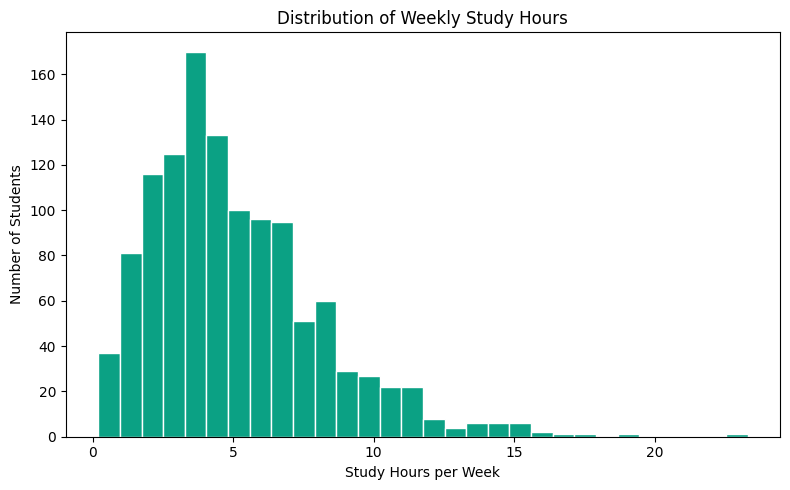

In [9]:
plt.figure(figsize=(8,5))

students["study_hours"].plot(
    kind="hist",
    bins=30,
    color="#0BA184",
    edgecolor="white"
)

plt.title(
    "Distribution of Weekly Study Hours"
)

plt.xlabel("Study Hours per Week")
plt.ylabel("Number of Students")

plt.tight_layout()

plt.savefig(
    "figures/study_hours_hist.png",
    dpi=150
)

plt.show()

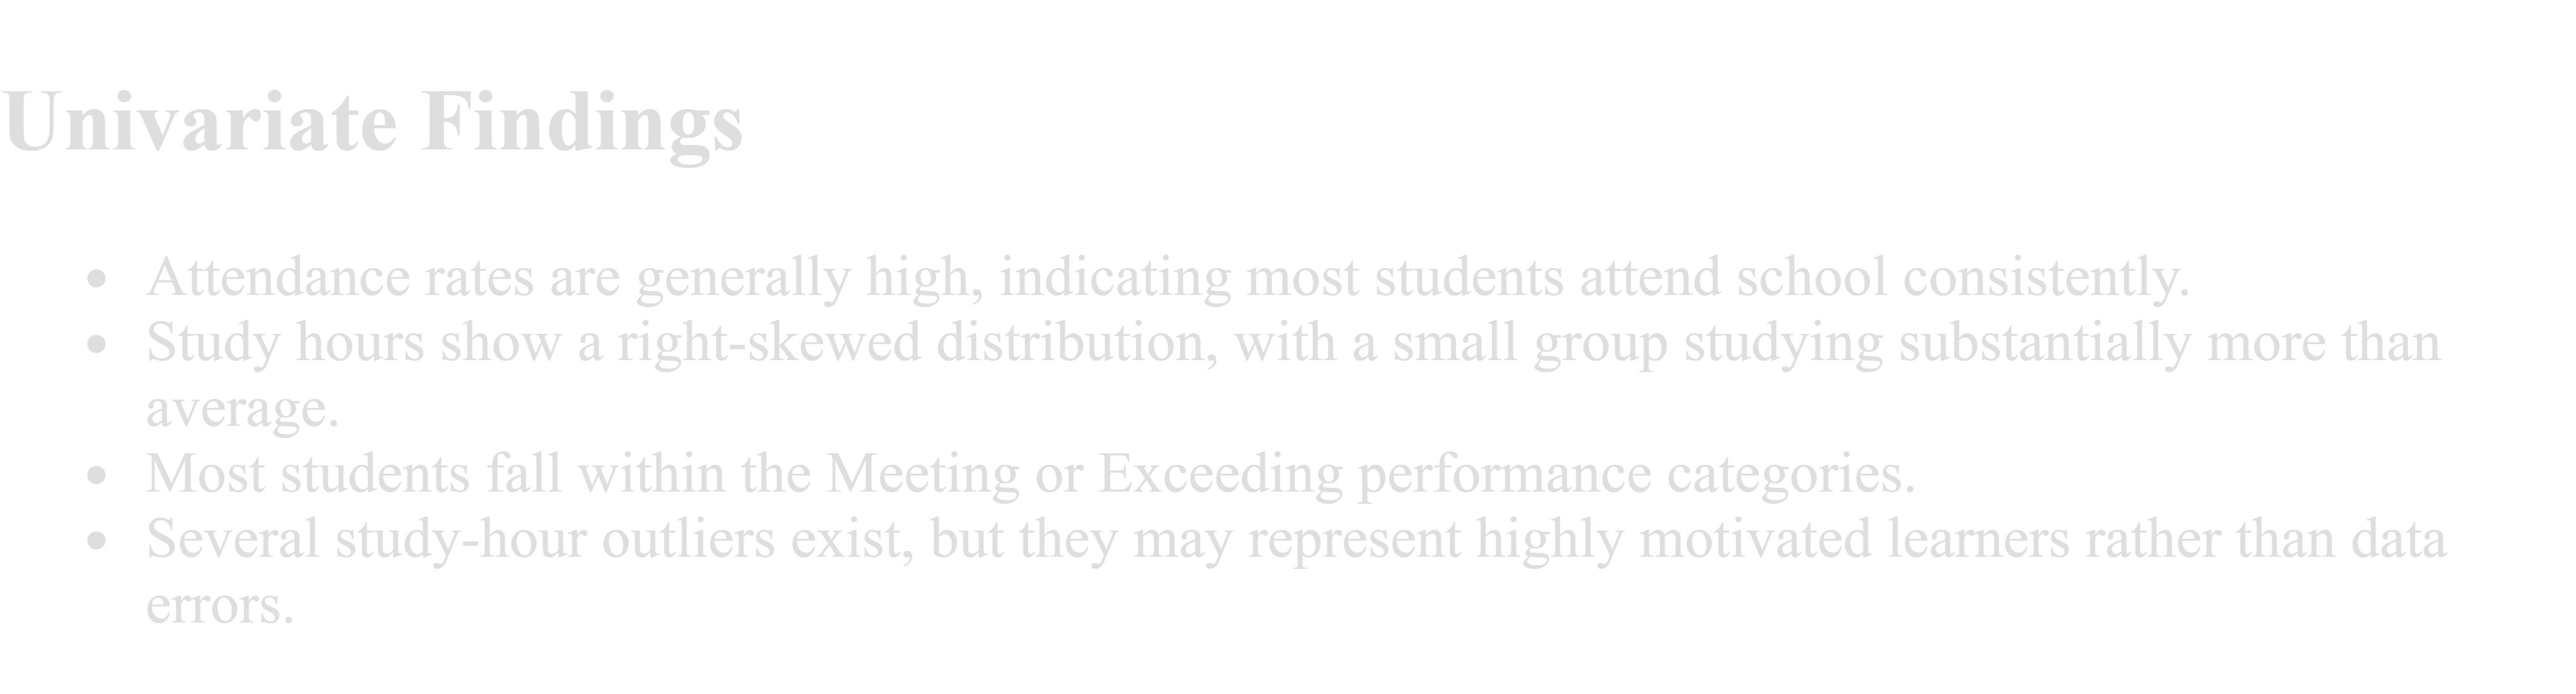

In [10]:
corr_matrix = (
    students[num_cols]
    .corr()
    .round(3)
)

print("=== Correlation Matrix ===")
display(corr_matrix)

corr_matrix.to_csv(
    "reports/correlation_matrix.csv"
)

print("\nSaved to reports/correlation_matrix.csv")

=== Correlation Matrix ===


,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.000,-0.029,0.300,0.327,0.260,0.359
study_hours,-0.029,1.000,0.560,0.624,0.550,0.704
math,0.300,0.560,1.000,0.559,0.459,0.814
english,0.327,0.624,0.559,1.000,0.502,0.827
science,0.260,0.550,0.459,0.502,1.000,0.815
average_score,0.359,0.704,0.814,0.827,0.815,1.000



Saved to reports/correlation_matrix.csv


In [11]:
print(
    corr_matrix["average_score"]
    .drop("average_score")
    .sort_values(ascending=False)
)

english            0.827
science            0.815
math               0.814
study_hours        0.704
attendance_rate    0.359
Name: average_score, dtype: float64


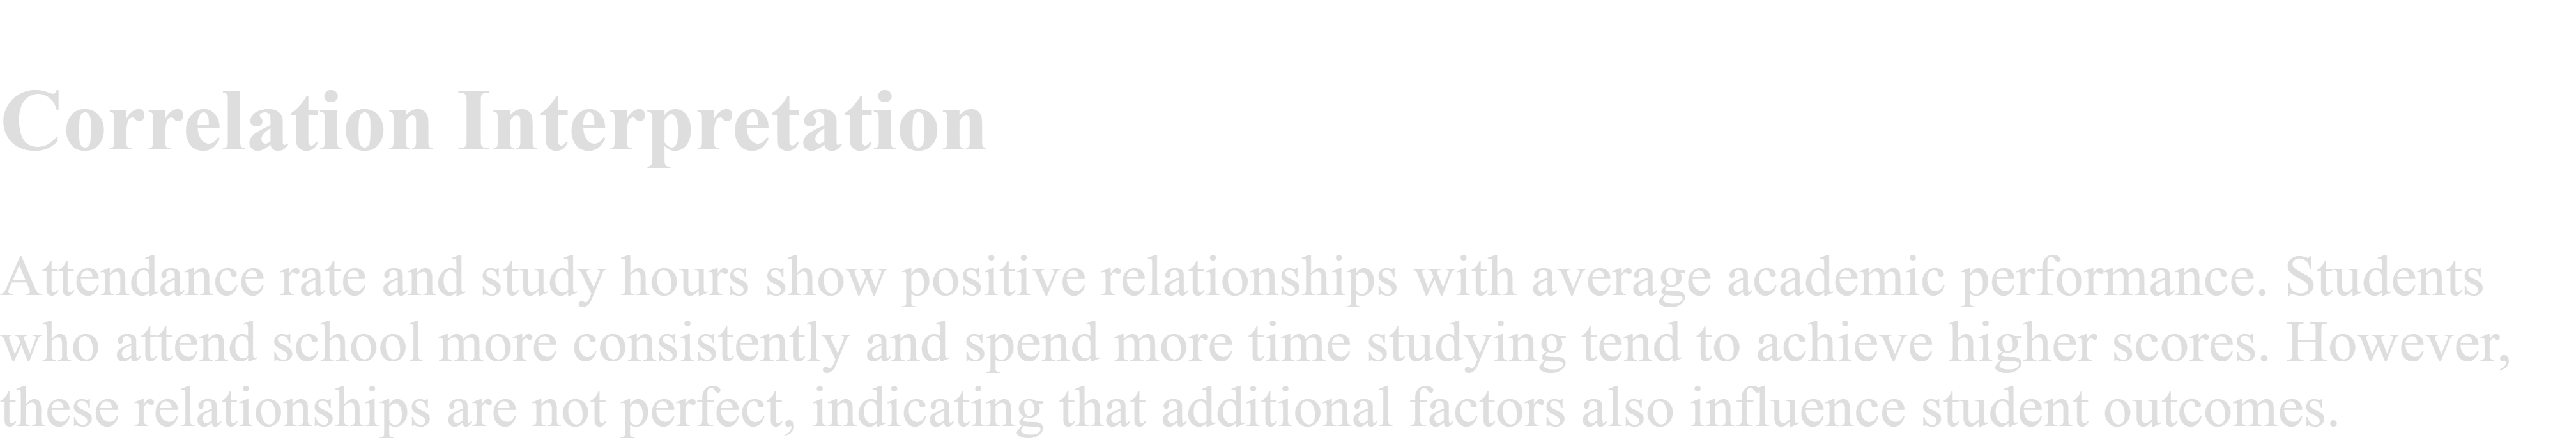

In [12]:
gender_summary = (
    students
    .groupby("gender")["average_score"]
    .mean()
    .round(2)
)

print("Average Score by Gender")
display(gender_summary)

Average Score by Gender


,average_score
gender,
F,72.10
M,71.91


In [13]:
school_summary = (
    students
    .groupby("school_type")["average_score"]
    .mean()
    .round(2)
)

print("Average Score by School Type")
display(school_summary)

Average Score by School Type


,average_score
school_type,
Private,76.01
Public,70.46


In [14]:
public_scores = students.loc[
    students["school_type"] == "Public",
    "average_score"
]

private_scores = students.loc[
    students["school_type"] == "Private",
    "average_score"
]

t_stat, p_value = stats.ttest_ind(
    private_scores,
    public_scores,
    equal_var=False
)

print("T Statistic:", round(t_stat, 3))
print("P Value:", round(p_value, 5))

T Statistic: 10.285
P Value: 0.0


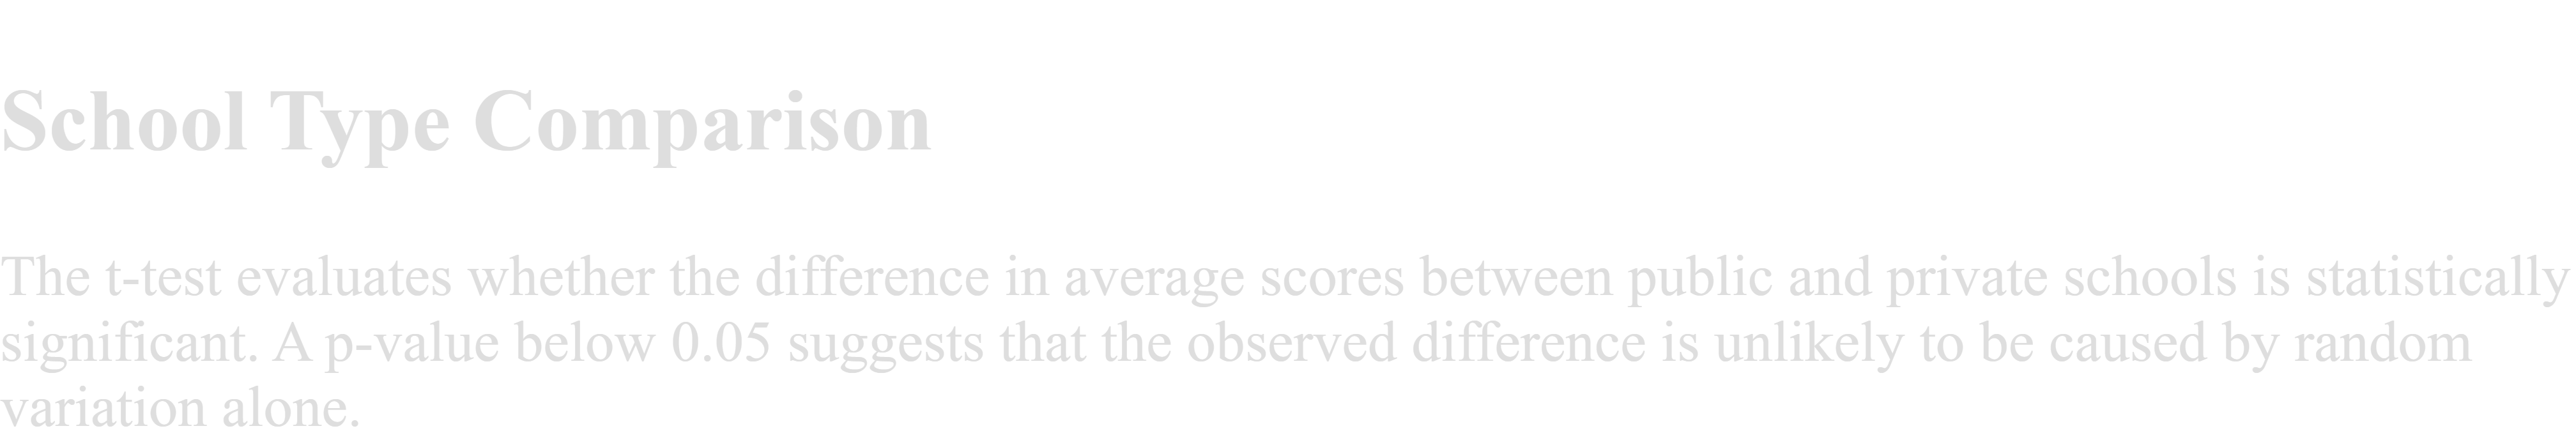

In [15]:
county_summary = (
    students
    .groupby("county")["average_score"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print("Average Score by County")
display(county_summary)

Average Score by County


,average_score
county,
Kisumu,73.07
Mombasa,72.17
Nairobi,71.96
Nyeri,71.94
Nakuru,71.84
Turkana,70.97


In [16]:
band_ct = pd.crosstab(
    students["county"],
    students["performance_band"],
    normalize="index"
).mul(100).round(1)

display(band_ct)

band_ct.to_csv(
    "reports/county_risk_summary.csv"
)

print(
    "Saved to reports/county_risk_summary.csv"
)

performance_band,At Risk,Meeting,Exceeding
county,,,
Kisumu,8.2,50.5,41.3
Mombasa,9.0,54.2,36.8
Nairobi,9.2,55.4,35.3
Nakuru,6.4,61.9,31.7
Nyeri,8.9,54.7,36.5
Turkana,7.9,59.7,32.5


Saved to reports/county_risk_summary.csv


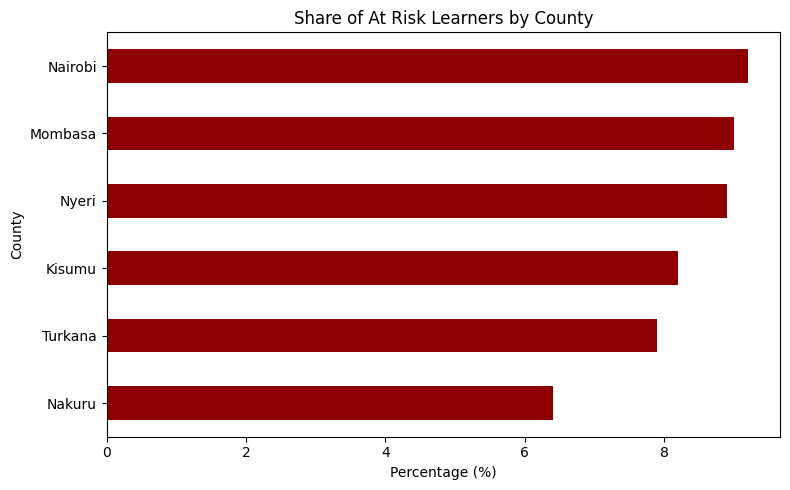

In [17]:
plt.figure(figsize=(8,5))

band_ct["At Risk"] \
    .sort_values() \
    .plot(
        kind="barh",
        color="#8E0000"
    )

plt.title(
    "Share of At Risk Learners by County"
)

plt.xlabel("Percentage (%)")
plt.ylabel("County")

plt.tight_layout()

plt.savefig(
    "figures/at_risk_by_county.png",
    dpi=150
)

plt.show()

<Figure size 800x500 with 0 Axes>

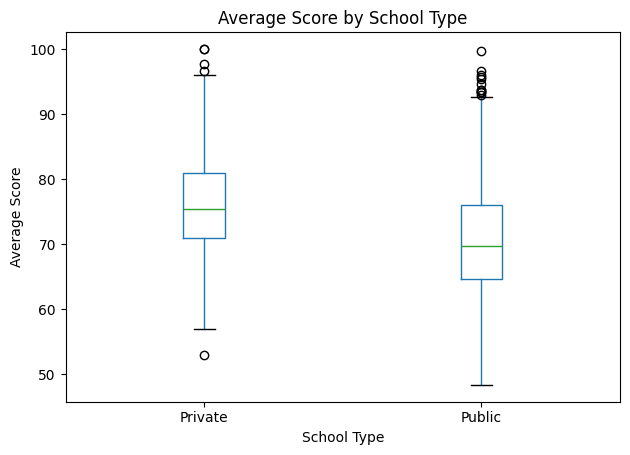

In [18]:
plt.figure(figsize=(8,5))

students.boxplot(
    column="average_score",
    by="school_type",
    grid=False
)

plt.title(
    "Average Score by School Type"
)

plt.suptitle("")

plt.xlabel("School Type")
plt.ylabel("Average Score")

plt.tight_layout()

plt.savefig(
    "figures/score_by_school_type.png",
    dpi=150
)

plt.show()

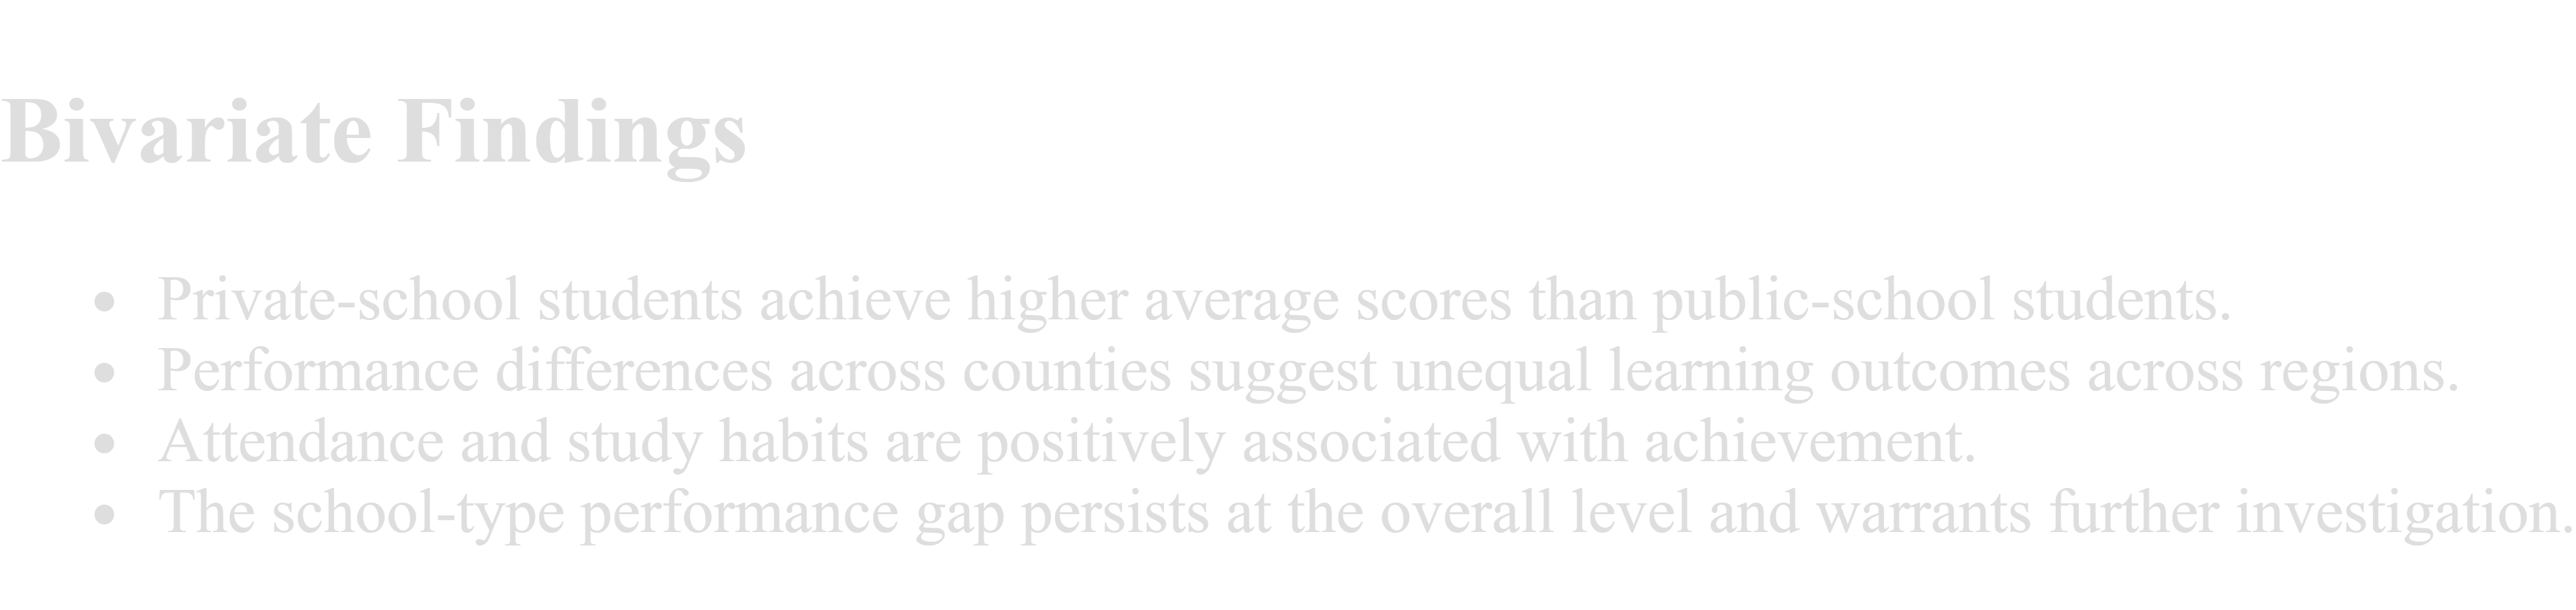

In [19]:
students["attendance_band"] = pd.cut(
    students["attendance_rate"],
    bins=[0, 0.70, 0.85, 1.00],
    labels=[
        "Low (<70%)",
        "Medium (70-85%)",
        "High (>85%)"
    ]
)

students["attendance_band"].value_counts()

,count
attendance_band,
Medium (70-85%),499
High (>85%),463
Low (<70%),238


In [20]:
students["study_quartile"] = pd.qcut(
    students["study_hours"],
    q=4,
    labels=[
        "Q1 (Lowest)",
        "Q2",
        "Q3",
        "Q4 (Highest)"
    ]
)

students["study_quartile"].value_counts()

,count
study_quartile,
Q1 (Lowest),311
Q2,302
Q4 (Highest),299
Q3,288


In [21]:
piv_att = pd.pivot_table(
    students,
    index="attendance_band",
    columns="school_type",
    values="average_score",
    aggfunc="mean",
    observed=True
).round(1)

piv_att["Gap (Private - Public)"] = (
    piv_att["Private"]
    - piv_att["Public"]
).round(1)

print(
    "Average Score by Attendance Band and School Type"
)

display(piv_att)

piv_att.to_csv(
    "reports/attendance_band_pivot.csv"
)

Average Score by Attendance Band and School Type


school_type,Private,Public,Gap (Private - Public)
attendance_band,,,
Low (<70%),71.5,64.9,6.6
Medium (70-85%),75.5,69.8,5.7
High (>85%),79.0,74.0,5.0


In [22]:
piv_study = pd.pivot_table(
    students,
    index="study_quartile",
    columns="school_type",
    values="average_score",
    aggfunc="mean",
    observed=True
).round(1)

piv_study["Gap (Private - Public)"] = (
    piv_study["Private"]
    - piv_study["Public"]
).round(1)

print(
    "Average Score by Study-Hour Quartile and School Type"
)

display(piv_study)

piv_study.to_csv(
    "reports/study_quartile_pivot.csv"
)

Average Score by Study-Hour Quartile and School Type


school_type,Private,Public,Gap (Private - Public)
study_quartile,,,
Q1 (Lowest),69.5,63.8,5.7
Q2,74.9,67.1,7.8
Q3,76.2,71.2,5.0
Q4 (Highest),83.6,80.1,3.5


In [23]:
slope, intercept = np.polyfit(
    students["study_hours"],
    students["average_score"],
    1
)

regression = stats.linregress(
    students["study_hours"],
    students["average_score"]
)

r2 = regression.rvalue ** 2

print(
    f"Trend Line: average_score = "
    f"{slope:.2f} × study_hours + {intercept:.2f}"
)

print(
    f"R² = {r2:.3f}"
)

Trend Line: average_score = 2.12 × study_hours + 61.26
R² = 0.495


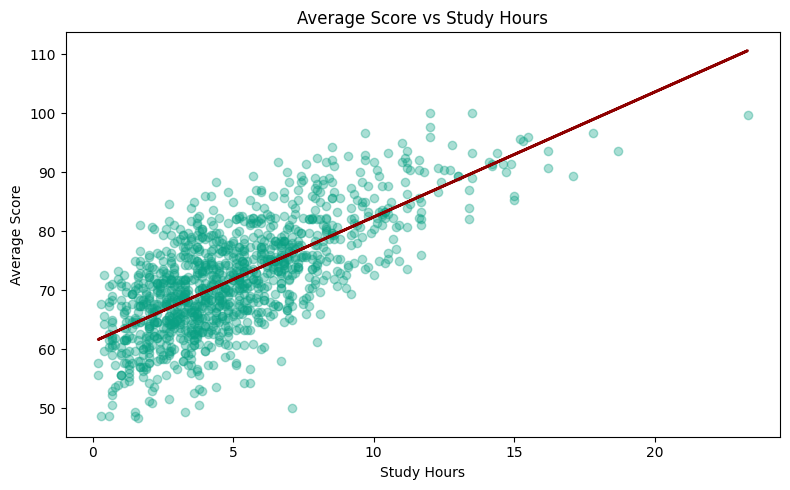

In [24]:
plt.figure(figsize=(8,5))

plt.scatter(
    students["study_hours"],
    students["average_score"],
    alpha=0.35,
    color="#0BA184"
)

x = students["study_hours"]

plt.plot(
    x,
    slope * x + intercept,
    color="#8E0000",
    linewidth=2
)

plt.title(
    "Average Score vs Study Hours"
)

plt.xlabel(
    "Study Hours"
)

plt.ylabel(
    "Average Score"
)

plt.tight_layout()

plt.savefig(
    "figures/study_hours_regression.png",
    dpi=150
)

plt.show()

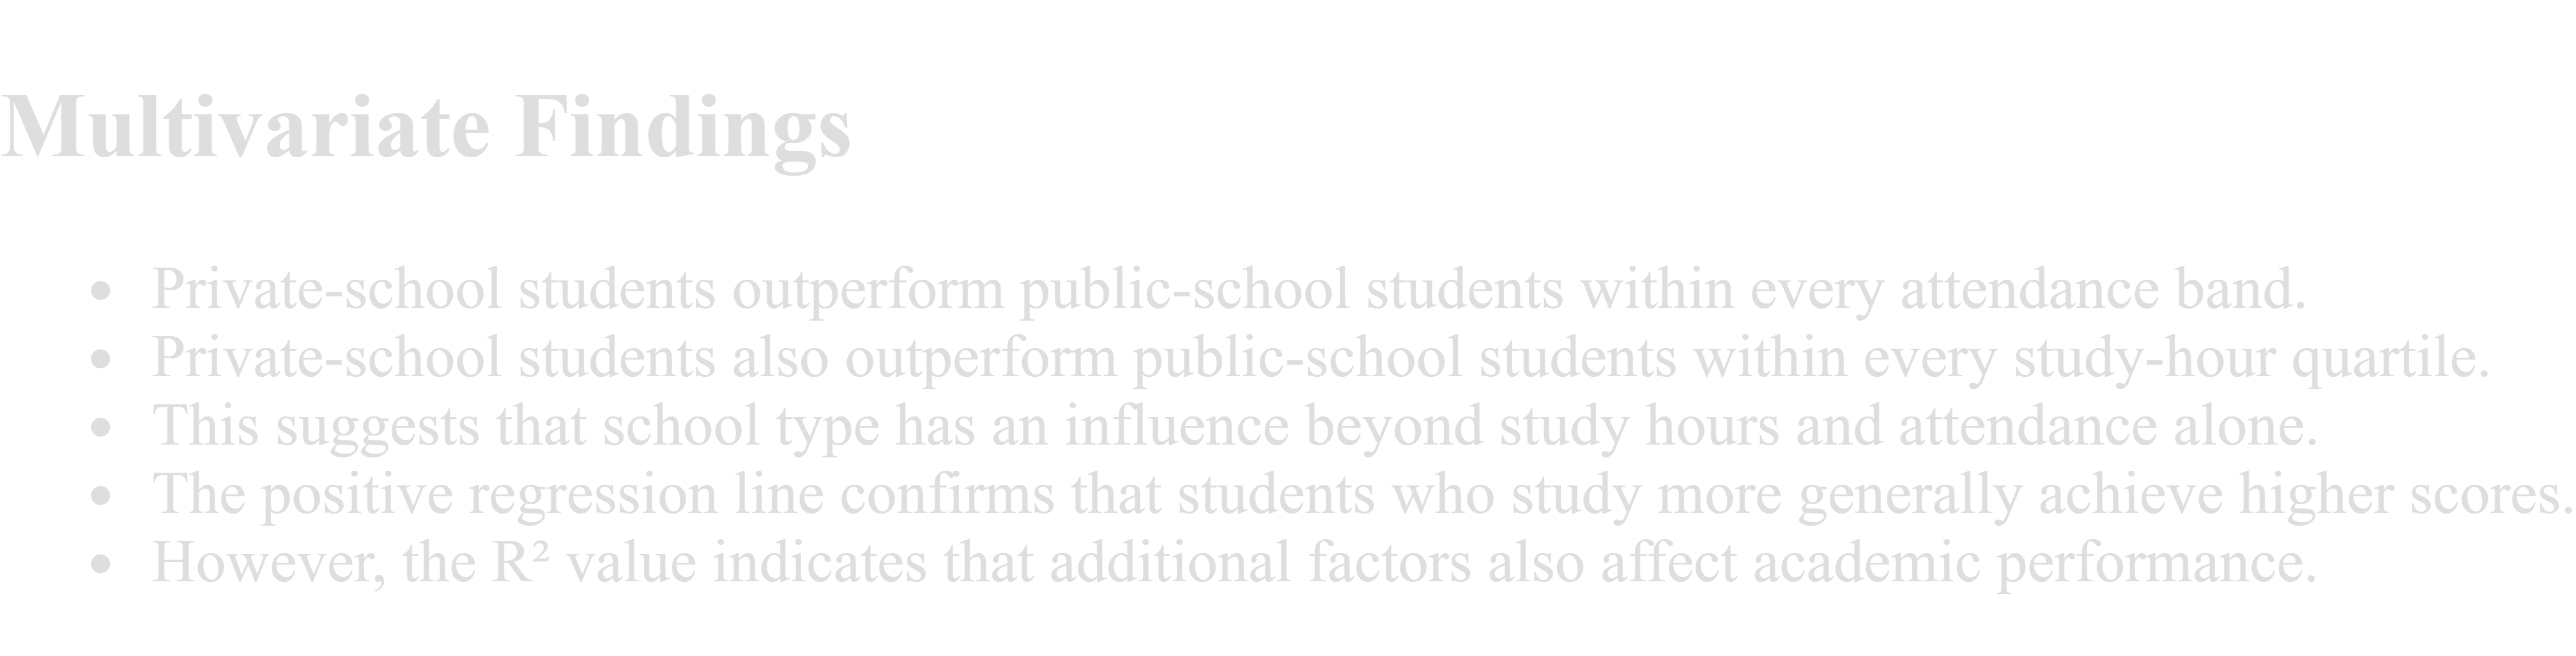

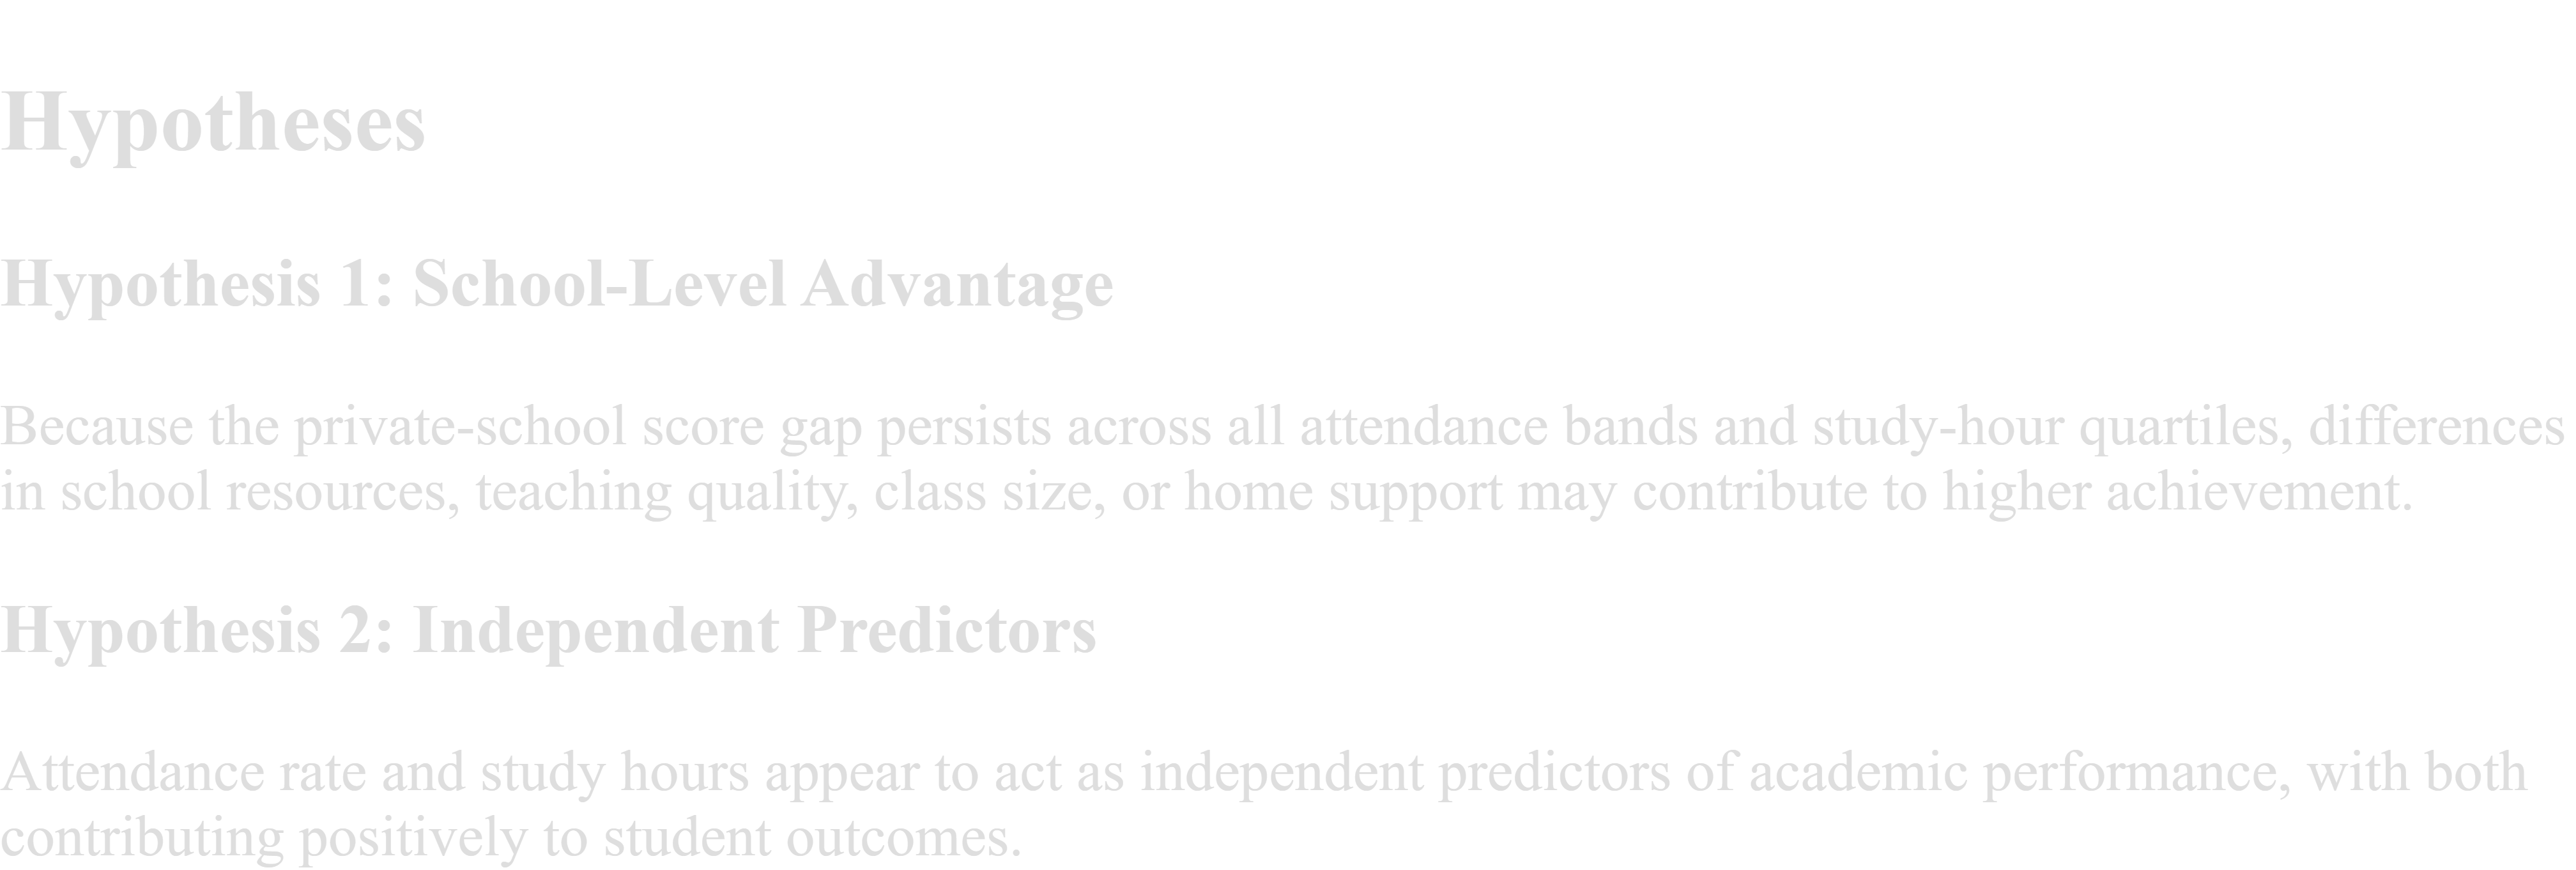

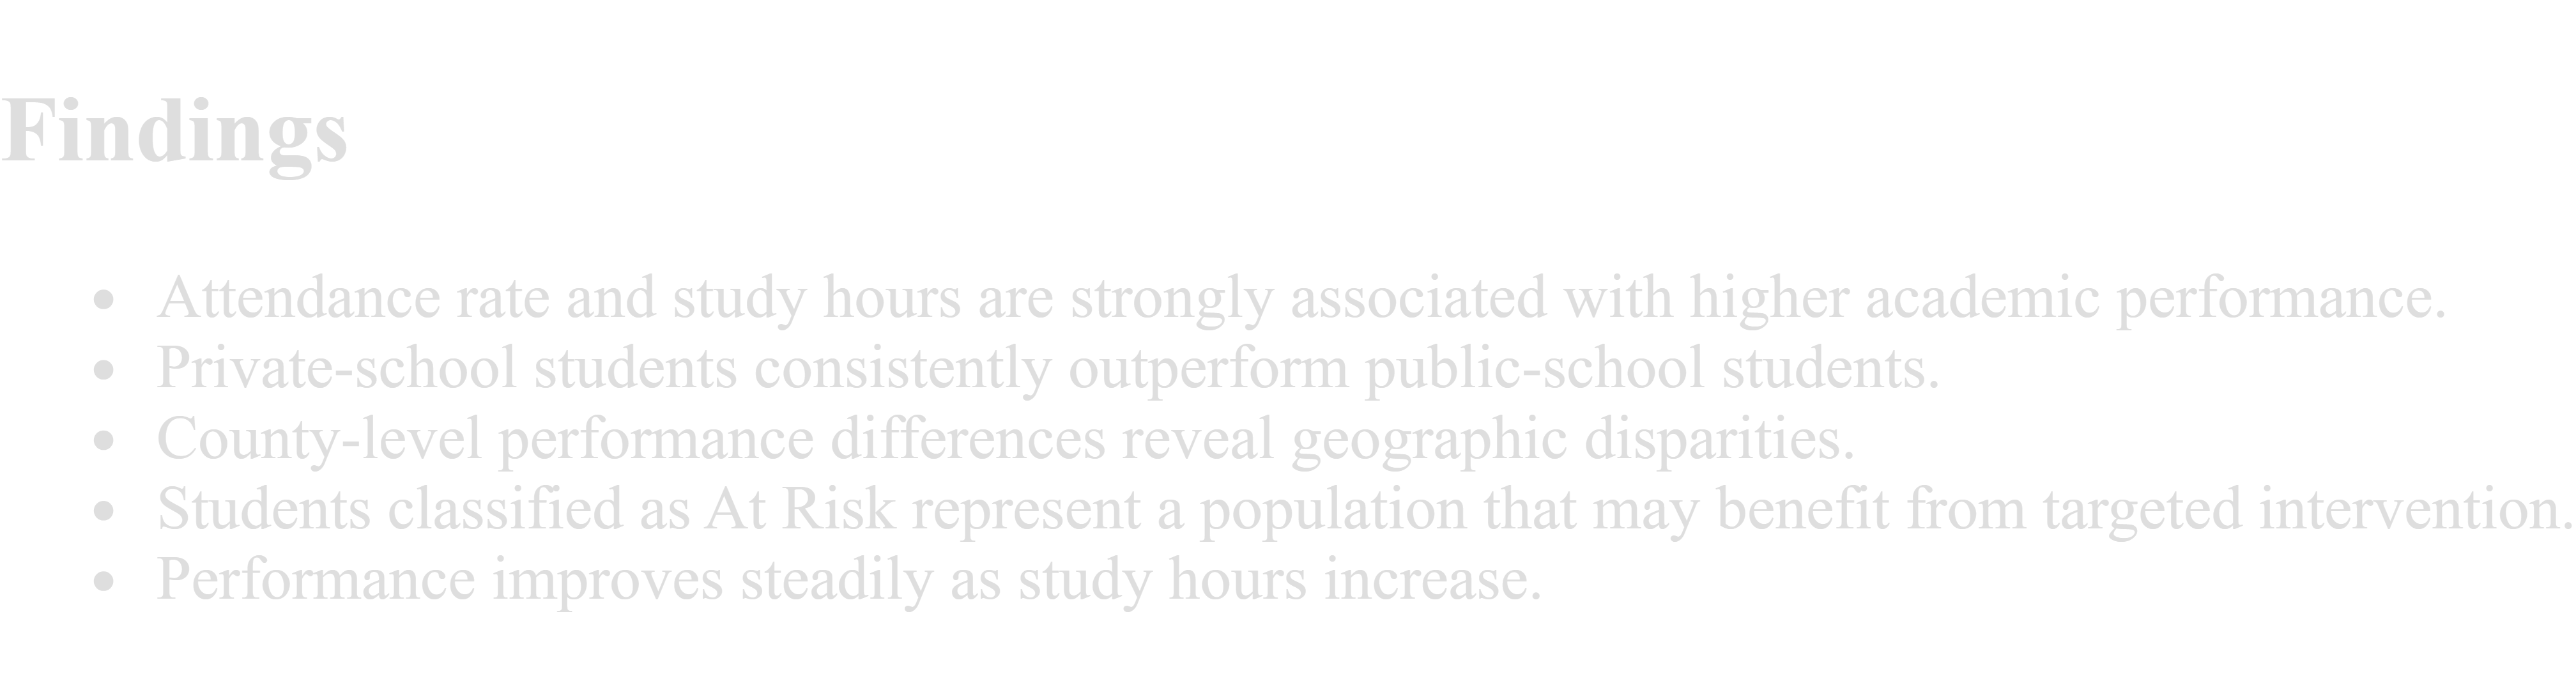

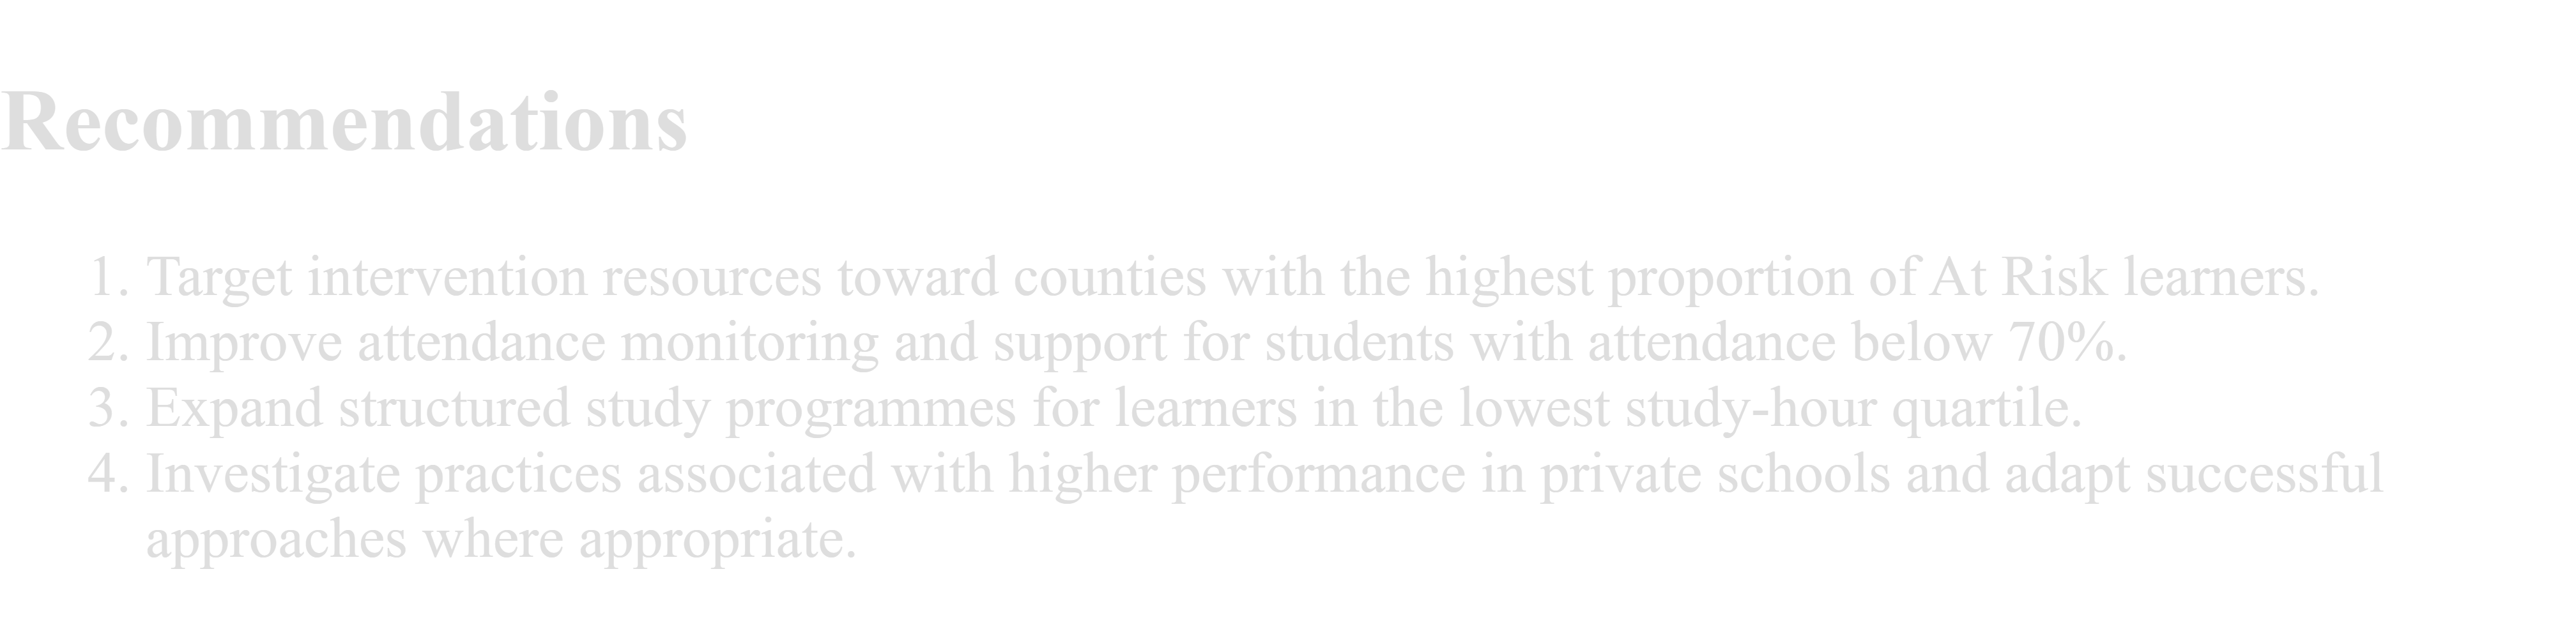

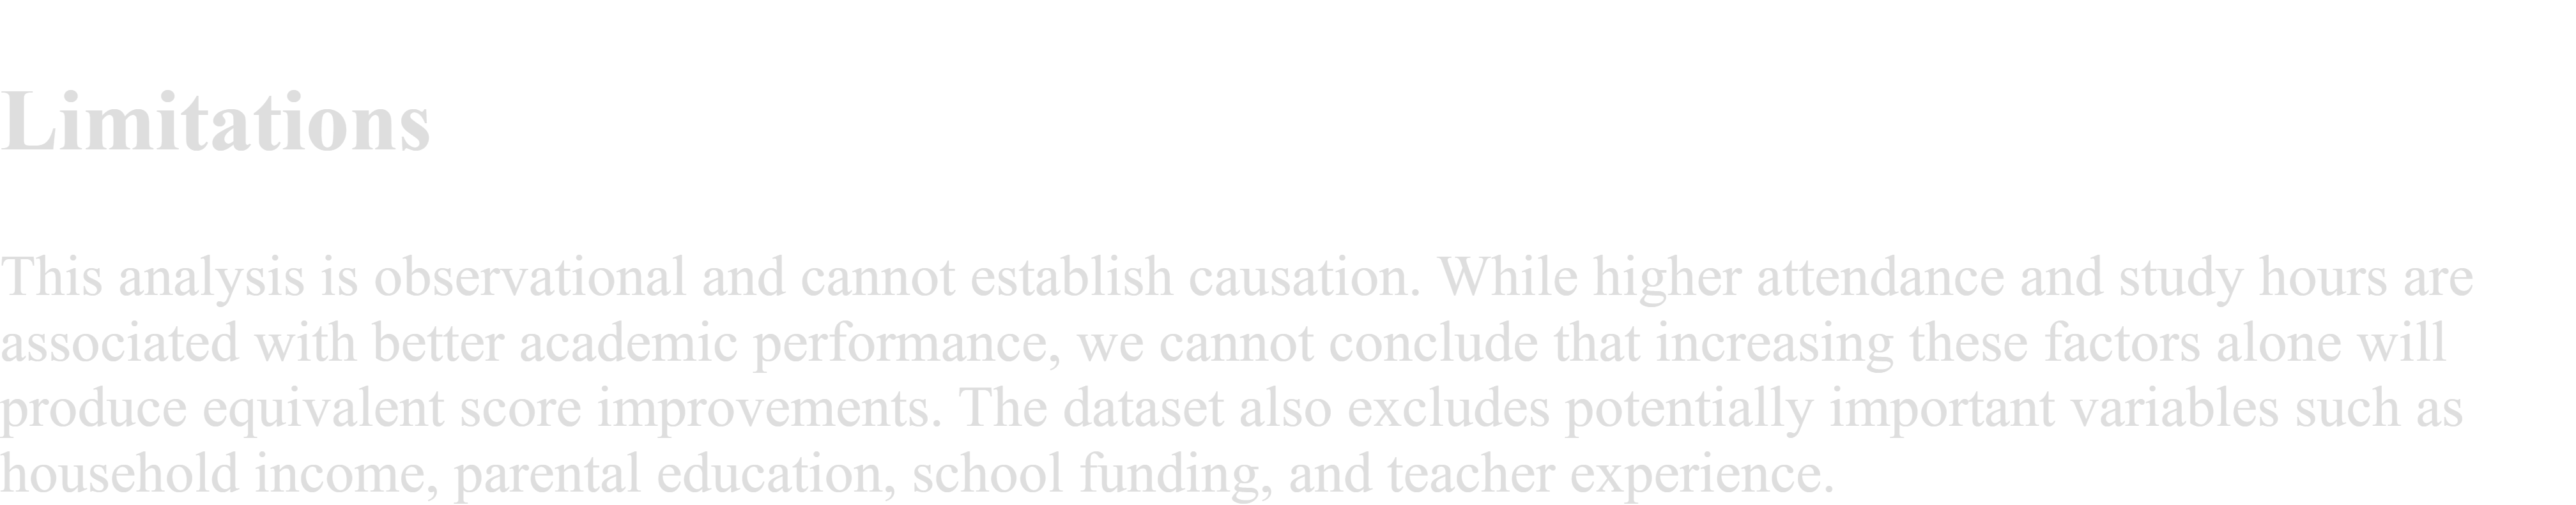

In [25]:
students.to_csv(
    "reports/student_performance_enriched.csv",
    index=False
)

print(
    "Final enriched dataset saved successfully."
)

Final enriched dataset saved successfully.


In [26]:
print("Notebook completed successfully.")

print(
    "\nGenerated Files:"
)

print("- reports/univariate_summary.csv")
print("- reports/correlation_matrix.csv")
print("- reports/county_risk_summary.csv")
print("- reports/attendance_band_pivot.csv")
print("- reports/study_quartile_pivot.csv")
print("- reports/student_performance_enriched.csv")

print("\nGenerated Figures:")

print("- figures/study_hours_hist.png")
print("- figures/at_risk_by_county.png")
print("- figures/score_by_school_type.png")
print("- figures/study_hours_regression.png")

Notebook completed successfully.

Generated Files:
- reports/univariate_summary.csv
- reports/correlation_matrix.csv
- reports/county_risk_summary.csv
- reports/attendance_band_pivot.csv
- reports/study_quartile_pivot.csv
- reports/student_performance_enriched.csv

Generated Figures:
- figures/study_hours_hist.png
- figures/at_risk_by_county.png
- figures/score_by_school_type.png
- figures/study_hours_regression.png
